# First EOD phase only: shape only vs per-fish × per-pair gains vs global g0 × L^0.25 (4-fish, Kaden masks, isolated 10 cm / 5×)

EODs: the isolated (sure-emitter) EODs at **10 cm / 5×** from all five videos (no mask QC).
- **Isolated**: the fish's mask midline ≥ 10 cm from every other fish's; at its top pair p* its predicted |v| ≥ 5× every other
  fish's; the largest recorded |v| is at p* with the predicted sign; only one fish passes.
- **Prediction** $m$: my model (BEM conductivities, sink at the tail tip, unit current) for that fish, with its **own sign** (no
  × −1).
- **Recorded** $r$: the 10-pair pattern at the **first phase** of the EOD. Each pair's 25-sample trace is demeaned; on the pair with
  the largest |V|, the main (largest) phase is at sample $t_2$ and the first phase is the opposite-sign extremum before it, at
  sample $t_1$; $r$ = all 10 pairs at $t_1$. EODs whose first phase is not at samples 8–11 or main phase not at 11–14 are left out.
  - The first phase is ~0.57 × the main phase (median) and has the sign of the raw model at the model's peak pair in every isolated
    EOD; the main phase (used before) has the opposite sign, which is why the model was multiplied by −1 there.

**Fits** (both by plain least squares on the recorded voltages, no per-EOD normalisation, so loud EODs near an electrode carry
the most weight; **every gain constrained to be ≥ 0**, so the model's sign is never flipped):
- **per-fish × per-pair**: $\min \sum_{i,p} (r_{i,p} - a_f b_p m_{i,f,p})^2$, 4 fish gains $a_f$ and 10 pair gains $b_p$ shared by
  all fish; alternating least squares with each update clipped at 0 (with $b$ fixed, $a_f = \max(0, \sum r\,(bm)/\sum (bm)^2)$
  over fish f's EODs; with $a$ fixed, $b_p = \max(0, \sum r\,(am)/\sum (am)^2)$ over pair p of every EOD; each is the exact
  minimiser of its one-variable problem under the constraint; 200 iterations from 1); $b$ then scaled to a geometric mean of 1
  (only $a_f b_p$ is determined; no prediction changes).
- **global $g_0 L^{0.25}$**: $\min \sum_{i,p} (r_{i,p} - g_0 L_f^{0.25} m_{i,f,p})^2$, so $g_0 = \max(0, \sum r\,(L^{0.25} m) / \sum (L^{0.25} m)^2)$;
  $L_f$ = 90th percentile of the fish's mask-midline length over all EOD frames of the five videos.

Both are fitted on four videos and applied to the fifth (**held out**).

**Errors, all on the same scale**, $\lVert r - \hat r\rVert / \max|r|$:
- shape only: $\hat r = m \cdot \max|r| / \max|m|$ (= L2 of the two patterns each scaled to max |v| = 1, signs kept);
- per-fish × per-pair: $\hat r = a_f b_p m$;
- global: $\hat r = g_0 L_f^{0.25} m$.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from eod_assign import load_electrode_pairs, recorded_pair_traces_all
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
SRC = f'{BASE}/fish_pair_factors_iso10cm_dom5'
OUT = f'{BASE}/fish_pair_factors_threshold_grid/l2_isolated_first_peak'; os.makedirs(OUT, exist_ok=True)
PIDS = [p for p, _, _ in load_electrode_pairs('data/electrodes/electrodes_signed_px_coord_4-fish.csv', 912)]
E, P, PX_CM = 0.25, 912, 912 / 60
SH, V1, V2 = 'shape only', 'per-fish × per-pair gains', 'global g0 × L^0.25'
COL = {SH: '#C9C9C3', V1: '#85857F', V2: '#33332F'}
LABEL = {SH: 'shape only (prediction scaled to this EOD\'s recorded peak)',
         V1: 'per-fish × per-pair gains (4 + 10, least squares on the other 4 videos)',
         V2: 'global g0 × L^0.25 (least squares on the other 4 videos)'}
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
peak = lambda x: np.abs(x).max(axis=-1, keepdims=True)

S0 = pd.read_csv(f'{SRC}/sure_emitter_eods.csv')
RECS = list(dict.fromkeys(S0.video))
R, M, R_main, keep, lens, T1 = [], [], [], [], {}, []
for t in RECS:
    g = S0[S0.video == t]
    z = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    fi = g.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy()
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)])
    Vt = recorded_pair_traces_all(df.iloc[g.row.to_numpy()], PIDS, 25); del df          # (n, 10, 25), each pair demeaned
    i = np.arange(len(Vt)); w = Vt[i, np.abs(Vt).max(2).argmax(1)]                       # trace of the pair with the largest |V|
    t2 = np.abs(w).argmax(1); s2 = np.sign(w[i, t2])
    t1 = np.array([np.argmax(-s2[k] * w[k, :t2[k]]) if t2[k] > 0 else -1 for k in i])    # opposite-sign extremum before the main phase
    ok = (t1 >= 8) & (t1 <= 11) & (t2 >= 11) & (t2 <= 14)
    keep.append(ok); T1.append(t1)
    R.append(Vt[i, :, t1][ok]); M.append(-z['mine_unit_current'][g.row.to_numpy(), fi][ok])          # raw model sign (undo x -1)
    R_main.append(z['recorded_peak'][g.row.to_numpy()][ok])
    mids = np.load(f'{BASE}/{t}/midlines_by_frame.npz')['mids']               # (n, 4, 101, 2), (row, col) / (P - 1)
    lens[t] = np.linalg.norm(np.diff(mids, axis=2), axis=-1).sum(-1) * (P - 1) / PX_CM
assert (S0.video.to_numpy() == np.concatenate([S0.video[S0.video == t].to_numpy() for t in RECS])).all()
keep = np.concatenate(keep); S = S0[keep].reset_index(drop=True); S['first-phase sample'] = np.concatenate(T1)[keep]
R, M, R_main = np.concatenate(R), np.concatenate(M), np.concatenate(R_main)
pk = np.abs(M).argmax(1); ii = np.arange(len(M))
print(f'{keep.sum()} of {len(keep)} isolated EODs kept (first phase at samples 8-11, main phase at 11-14)')
print(f'first phase: recorded sign = raw model sign at the model peak pair in {(np.sign(R[ii, pk]) == np.sign(M[ii, pk])).mean() * 100:.1f}%; '
      f'largest recorded pair = model peak pair in {(np.abs(R).argmax(1) == pk).mean() * 100:.1f}%; '
      f'first / main phase amplitude at that pair: median {np.median(np.abs(R[ii, pk]) / np.abs(R_main[ii, pk])):.2f}')
FI = S.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy(); V = S.video.to_numpy()
L = np.array([np.percentile(np.concatenate([lens[t][np.isfinite(lens[t][:, j]), j] for t in RECS]), 90) for j in range(4)])
L_VIDEO = pd.DataFrame({t: [np.nanpercentile(lens[t][:, j], 90) for j in range(4)] for t in RECS}, index=list(LET))
print('fish length L (cm, 90th percentile of the mask midline, all five videos):', dict(zip(LET, L.round(2))))
display(L_VIDEO.round(2).rename_axis('fish (per video, cm)'))

def fit(R, M, fi, iters=200):
    '''Plain least squares, R ~ a[fi, None] * b[None] * M with a, b >= 0 (each ALS update clipped at 0); geometric mean of b = 1.'''
    a, b = np.ones(4), np.ones(10)
    for _ in range(iters):
        X = M * b
        a = np.array([max(0.0, (R[fi == f] * X[fi == f]).sum() / (X[fi == f] ** 2).sum()) if (fi == f).any() else np.nan for f in range(4)])
        Y = M * a[fi, None]; b = np.maximum(0.0, (R * Y).sum(0) / (Y ** 2).sum(0))
    pos = b > 0
    c = np.exp(np.mean(np.log(b[pos]))) if pos.any() else 1.0
    return a * c, b / c

def fit_g0(R, M, fi, L):
    X = L[fi, None] ** E * M
    return max(0.0, (R * X).sum() / (X ** 2).sum())

D = S[['video', 'row', 'Frame', 'emitter', 'pair p* (1-10)', 'gap (cm)', 'first-phase sample']].copy()
D[SH] = np.linalg.norm(R / peak(R) - M / peak(M), axis=1)
D[V1] = np.nan; D[V2] = np.nan; D['max |r| (V)'] = peak(R)[:, 0]
held = []
for t in RECS:
    tr, te = V != t, V == t
    a, b = fit(R[tr], M[tr], FI[tr]); g0 = fit_g0(R[tr], M[tr], FI[tr], L)
    D.loc[te, V1] = np.linalg.norm(R[te] - a[FI[te], None] * b[None] * M[te], axis=1) / peak(R[te])[:, 0]
    D.loc[te, V2] = np.linalg.norm(R[te] - g0 * L[FI[te], None] ** E * M[te], axis=1) / peak(R[te])[:, 0]
    held.append(dict(video=t, g0=g0, **{f'fish {f}': a[j] for j, f in enumerate(LET)}, **{f'pair {p + 1}': b[p] for p in range(10)}))
H = pd.DataFrame(held).set_index('video'); H.to_csv(f'{OUT}/gains_fit_without_each_video_first_peak.csv')
D.to_csv(f'{OUT}/l2_isolated_10cm_5x_first_peak.csv', index=False)
print('g0 fitted without each video:', H.g0.round(4).to_dict())

G = D.groupby('emitter')
T = pd.DataFrame({'n EODs': G.size(), **{f'median L2, {m}': G[m].median() for m in COL},
                  **{f'% EODs where {v} < shape only': G[[v, SH]].apply(lambda d: (d[v] < d[SH]).mean() * 100) for v in (V1, V2)}})
T.loc['all'] = [len(D), *[D[m].median() for m in COL], *[(D[v] < D[SH]).mean() * 100 for v in (V1, V2)]]
T['n EODs'] = T['n EODs'].astype(int)
T.index = [f'fish {i}' if i != 'all' else 'all fish' for i in T.index]
T.to_csv(f'{OUT}/l2_isolated_10cm_5x_first_peak_medians.csv')
display(T.round(3))

26830 of 26926 isolated EODs kept (first phase at samples 8-11, main phase at 11-14)
first phase: recorded sign = raw model sign at the model peak pair in 100.0%; largest recorded pair = model peak pair in 99.5%; first / main phase amplitude at that pair: median 0.59
fish length L (cm, 90th percentile of the mask midline, all five videos): {'A': np.float64(15.65), 'B': np.float64(13.1), 'C': np.float64(9.82), 'D': np.float64(8.51)}


,05_52_55,06_52_55,11_12_57,15_16_23,19_16_25
"fish (per video, cm)",,,,,
A,15.67,15.59,15.65,15.65,15.66
B,13.12,13.16,13.06,12.95,12.74
C,9.90,9.78,9.83,9.76,9.80
D,8.51,8.40,8.26,8.56,8.52


g0 fitted without each video: {'05_52_55': 0.1018, '06_52_55': 0.1204, '11_12_57': 0.1125, '15_16_23': 0.1132, '19_16_25': 0.1135}


,n EODs,"median L2, shape only","median L2, per-fish × per-pair gains","median L2, global g0 × L^0.25",% EODs where per-fish × per-pair gains < shape only,% EODs where global g0 × L^0.25 < shape only
fish A,6240,0.211,0.254,0.462,36.474,8.686
fish B,15492,0.224,0.451,0.733,6.875,13.626
fish C,1984,0.193,0.384,0.445,22.177,10.131
fish D,3114,0.206,0.460,0.523,8.510,11.689
all fish,26830,0.219,0.414,0.536,15.080,11.994


## L2 per fish

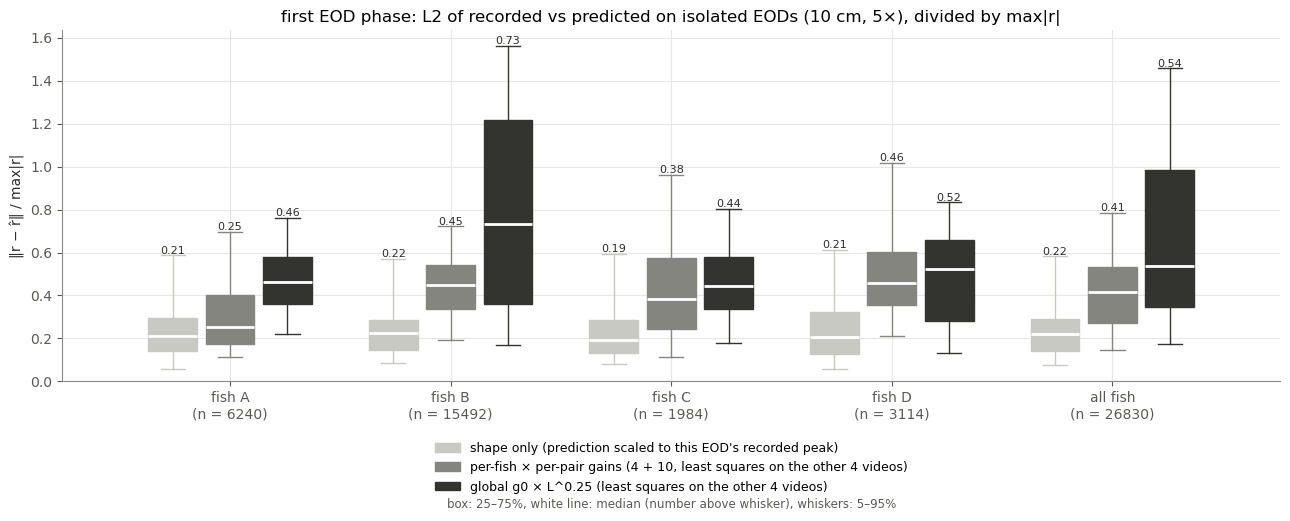

In [2]:
fig, ax = plt.subplots(figsize=(13, 5.6))
groups = list(LET) + ['all']; w = 0.26
for k, (m, c) in enumerate(COL.items()):
    data = [D.loc[D.emitter == f, m].to_numpy() if f != 'all' else D[m].to_numpy() for f in groups]
    pos = np.arange(len(groups)) + (k - 1) * w
    ax.boxplot(data, positions=pos, widths=w * 0.85, whis=(5, 95), showfliers=False, patch_artist=True,
               medianprops=dict(color='white', lw=2), whiskerprops=dict(color=c), capprops=dict(color=c), boxprops=dict(facecolor=c, edgecolor=c))
    for x, v in zip(pos, data):
        ax.text(x, np.percentile(v, 95), f'{np.median(v):.2f}', ha='center', va='bottom', fontsize=8, color='#2b2b2b')
ax.set(xticks=range(len(groups)), xticklabels=[f'fish {f}\n(n = {(D.emitter == f).sum()})' if f != 'all' else f'all fish\n(n = {len(D)})' for f in groups],
       ylabel='‖r − r̂‖ / max|r|', title='first EOD phase: L2 of recorded vs predicted on isolated EODs (10 cm, 5×), divided by max|r|', ylim=(0, None))
ax.legend(handles=[Patch(color=COL[m], label=LABEL[m]) for m in COL], frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), fontsize=9)
ax.text(0.5, -0.36, 'box: 25–75%, white line: median (number above whisker), whiskers: 5–95%', transform=ax.transAxes,
        ha='center', fontsize=8.5, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/l2_isolated_10cm_5x_first_peak.png', dpi=120, bbox_inches='tight'); plt.show()

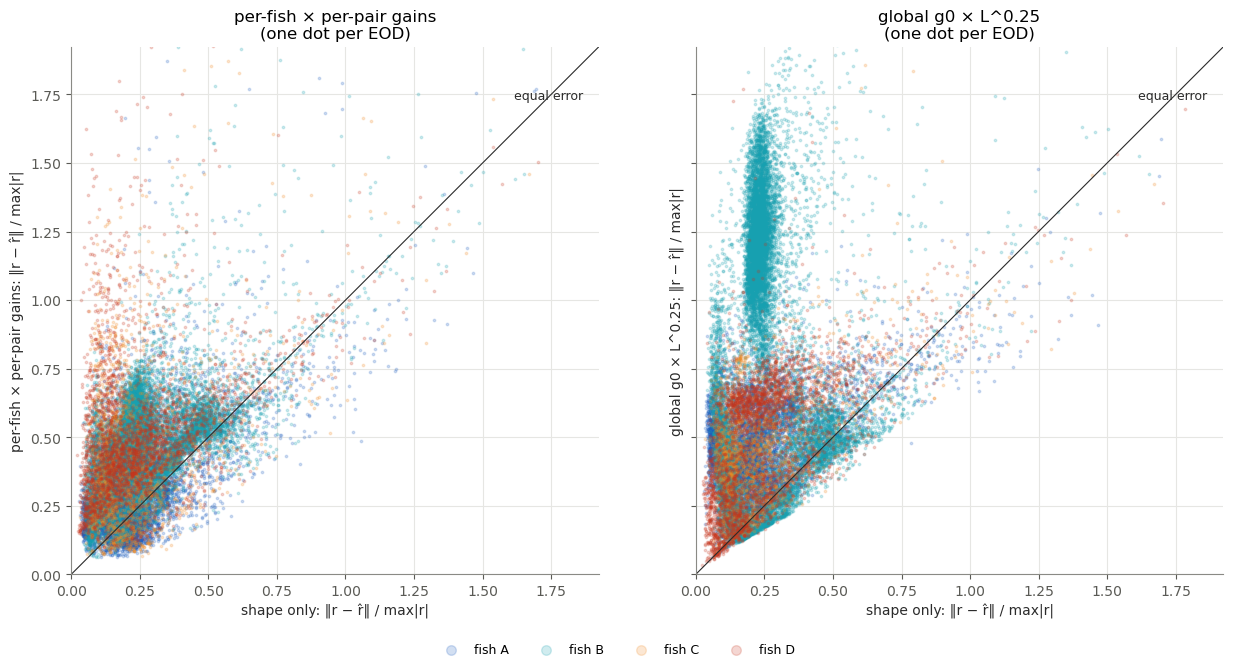

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True, sharey=True)
lim = np.percentile(np.r_[D[SH], D[V1], D[V2]], 99)
for ax, v in zip(axs, (V1, V2)):
    for f in LET:
        d = D[D.emitter == f]
        ax.scatter(d[SH], d[v], s=3, alpha=0.2, color=FISH_COL[f], label=f'fish {f}')
    ax.plot([0, lim], [0, lim], color='#2b2b2b', lw=0.8)
    ax.text(lim * 0.97, lim * 0.9, 'equal error', ha='right', fontsize=9, color='#2b2b2b')
    ax.set(xlim=(0, lim), ylim=(0, lim), aspect='equal', xlabel='shape only: ‖r − r̂‖ / max|r|', ylabel=f'{v}: ‖r − r̂‖ / max|r|',
           title=f'{v}\n(one dot per EOD)')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, markerscale=4, frameon=False, loc='lower center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.07))
plt.tight_layout(); fig.savefig(f'{OUT}/l2_isolated_10cm_5x_first_peak_scatter.png', dpi=120, bbox_inches='tight'); plt.show()

## Fish length vs per-fish gain

Per-fish gains $a_f$ of the per-fish × per-pair fit on the first phase (plain least squares, gains ≥ 0, pair gains at a
geometric mean of 1):
- **large dots**: fit on all five videos, x = the fish's length over all five videos, with 95% bootstrap intervals (200 resamples
  of the EODs);
- **small dots**: one per fish and video: $a_f$ refitted on that video's EODs of the fish with the pair gains fixed to the
  all-video fit ($a_f = \sum r\,(bm)/\sum(bm)^2$), x = the fish's length in that video (90th percentile of its mask midline);
  only fish-videos with ≥ 20 isolated EODs.

Lines: the global fit's $g_0 L^{0.25}$ (all five videos), and a power law $c\,L^{e}$ fitted to the small dots (least squares on
log a vs log L, each fish-video counted once).

In [4]:
a_all, b_all = fit(R, M, FI); g0_all = fit_g0(R, M, FI, L)
rng = np.random.default_rng(0)
boot = np.array([fit(R[i], M[i], FI[i], iters=60)[0] for i in (rng.integers(0, len(R), len(R)) for _ in range(200))])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
pts = []
for t in RECS:
    for j, f in enumerate(LET):
        k = (V == t) & (FI == j)
        if k.sum() < 20: continue
        X = M[k] * b_all
        pts.append(dict(video=t, fish=f, L_cm=L_VIDEO.loc[f, t], a_f=max(0.0, (R[k] * X).sum() / (X ** 2).sum()), n=int(k.sum())))
PTS = pd.DataFrame(pts)
e_fit, logc = np.polyfit(np.log(PTS.L_cm), np.log(PTS.a_f), 1)
be = []
for _ in range(2000):                                                       # bootstrap over fish-videos
    s = PTS.sample(len(PTS), replace=True, random_state=rng.integers(1 << 31))
    if s.fish.nunique() > 1: be.append(np.polyfit(np.log(s.L_cm), np.log(s.a_f), 1)[0])
e_lo, e_hi = np.percentile(be, [2.5, 97.5])
a_main, b_main = fit(R_main, -M, FI)                                         # same EODs, main phase, model x -1 (as before)
FG = pd.DataFrame({'L (cm)': L, 'a_f, first phase': a_all, '95% low': lo, '95% high': hi, 'g0 L^0.25 (global fit)': g0_all * L ** E,
                   'a_f, main phase (as before)': a_main, 'first / main': a_all / a_main}, index=list(LET))
FG.to_csv(f'{OUT}/fish_length_vs_gain_first_peak.csv'); PTS.to_csv(f'{OUT}/fish_length_vs_gain_per_video_first_peak.csv', index=False)
display(pd.DataFrame({'pair gain, first phase': b_all, 'pair gain, main phase (as before)': b_main}, index=[f'pair {p}' for p in range(1, 11)]).round(3))
display(FG.round(3)); display(PTS.round(3))
print(f'power law through the fish-video points: a = {np.exp(logc):.3f} L^{e_fit:.2f} (exponent 95% bootstrap over fish-videos {e_lo:.2f} to {e_hi:.2f})')
print(f'global fit: g0 = {g0_all:.4f}')

,"pair gain, first phase","pair gain, main phase (as before)"
pair 1,0.952,0.946
pair 2,0.744,0.754
pair 3,0.787,0.790
pair 4,0.869,0.870
pair 5,1.085,1.090
pair 6,1.339,1.336
pair 7,1.241,1.245
pair 8,1.234,1.231
pair 9,0.943,0.945
pair 10,0.984,0.967


,L (cm),"a_f, first phase",95% low,95% high,g0 L^0.25 (global fit),"a_f, main phase (as before)",first / main
A,15.647,0.297,0.296,0.299,0.223,0.454,0.655
B,13.100,0.166,0.165,0.167,0.214,0.291,0.570
C,9.815,0.250,0.247,0.253,0.199,0.446,0.560
D,8.508,0.228,0.226,0.231,0.192,0.418,0.546


,video,fish,L_cm,a_f,n
0,05_52_55,A,15.666,0.291,4199
1,05_52_55,B,13.116,0.136,1339
2,05_52_55,C,9.905,0.246,1784
3,05_52_55,D,8.508,0.220,1412
4,06_52_55,A,15.589,0.307,1465
5,06_52_55,B,13.162,0.137,6354
6,06_52_55,C,9.781,0.255,87
7,06_52_55,D,8.399,0.227,1078
8,11_12_57,B,13.059,0.160,472
9,11_12_57,D,8.255,0.266,514


power law through the fish-video points: a = 0.187 L^0.08 (exponent 95% bootstrap over fish-videos -0.62 to 0.54)
global fit: g0 = 0.1123


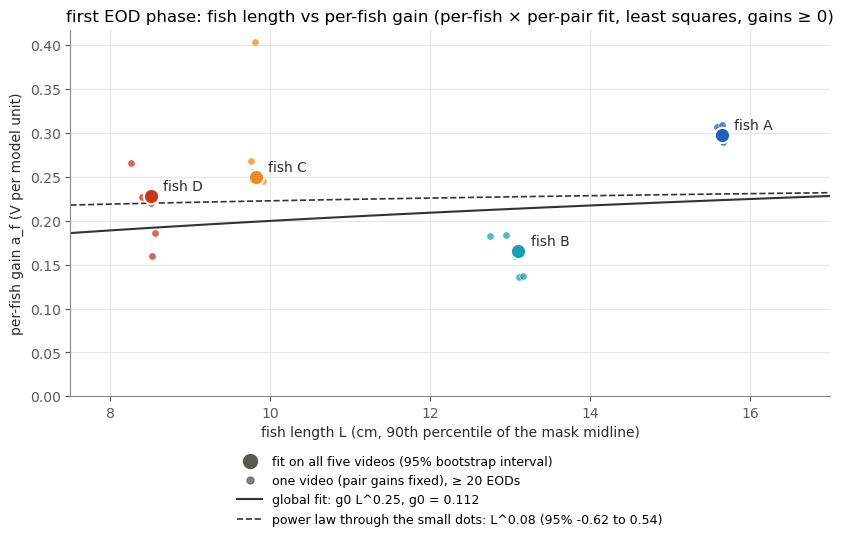

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
for j, f in enumerate(LET):
    p = PTS[PTS.fish == f]
    ax.scatter(p.L_cm, p.a_f, s=28, color=FISH_COL[f], alpha=0.75, edgecolor='white', lw=0.5, zorder=3)
    ax.errorbar(L[j], a_all[j], yerr=[[a_all[j] - lo[j]], [hi[j] - a_all[j]]], fmt='o', ms=11, color=FISH_COL[f],
                mec='white', mew=1.5, capsize=4, lw=1.2, zorder=4)
    ax.annotate(f'fish {f}', (L[j], a_all[j]), xytext=(9, 4), textcoords='offset points', fontsize=10, color='#2b2b2b')
xs = np.linspace(7.5, 17, 100)
ax.plot(xs, g0_all * xs ** E, color='#33332F', lw=1.5, label=f'global fit: g0 L^0.25, g0 = {g0_all:.3f}')
ax.plot(xs, np.exp(logc) * xs ** e_fit, color='#33332F', lw=1.2, ls='--',
        label=f'power law through the small dots: L^{e_fit:.2f} (95% {e_lo:.2f} to {e_hi:.2f})')
ax.set(xlabel='fish length L (cm, 90th percentile of the mask midline)', ylabel='per-fish gain a_f (V per model unit)',
       title='first EOD phase: fish length vs per-fish gain (per-fish × per-pair fit, least squares, gains ≥ 0)', ylim=(0, None), xlim=(7.5, 17))
h = [Line2D([], [], marker='o', ls='', ms=10, color='#5a5a55', label='fit on all five videos (95% bootstrap interval)'),
     Line2D([], [], marker='o', ls='', ms=5, color='#5a5a55', alpha=0.75, label='one video (pair gains fixed), ≥ 20 EODs')]
ax.legend(handles=h + ax.get_legend_handles_labels()[0], frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.13), fontsize=9)
plt.tight_layout(); fig.savefig(f'{OUT}/fish_length_vs_gain_first_peak.png', dpi=120, bbox_inches='tight'); plt.show()